# Three-section volumetric registration benchmark

Standalone bounded-tilt experiment using a shared autoencoder and volumetric splat field. No other notebook or checkpoint is required. Data use the ABC Atlas cache configured by `.env`.

**Primary task:** fit the two flanks, freeze the field, and recover an artificially displaced middle section using expression. Compare zero tilt with a 25-degree combined out-of-plane tilt bound, plus unregistered and oracle-coordinate controls. In-plane splat rotation is unrestricted. All section depths remain fixed. Centers remain between the flanking planes, but Gaussian support may extend beyond them.

**Scope:** this first stage estimates rigid x-y poses, not non-affine warps. It is not yet a matched comparison with the 2D PASTE/CAST benchmark. The optional joint experiment tests whether alternating pose/field updates recover known distortions or simply absorb them into the field.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, copy, ast
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv

ROOT = Path.cwd().resolve()
while not ((ROOT/'pyproject.toml').exists() and (ROOT/'paper').is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError('Repository root not found')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
load_dotenv(ROOT/'.env')
from spatsplat import GeneProfileAutoencoder, train_profile_autoencoder, evaluate_profile_autoencoder
from paper.data_loaders.allen_merfish_triplet import load_allen_merfish_triplet
from paper.volumetric_registration import (
    profiles, initialize_field, fit_field, evaluate_field, perturb,
    fit_transform, recovery_metrics, fit_joint,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pd.options.display.float_format = lambda x: f'{x:.4g}'
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'savefig.dpi':180})
SEED = 3107
SECTIONS = (24, 25, 26)  # Consecutive, equally spaced; avoid damaged section 27.
RUN_FIELD_FITS = True
RUN_REGISTRATION = True
RUN_JOINT = False
FORCE_RETRAIN = False
settings = dict(num_splats=1024, latent_dim=32, hidden_dim=128, top_k=64,
                sharpness=1.5, scale_xy=.04, tilt_weight=.01,
                field_epochs=100, steps_per_epoch=10, field_lr=.001,
                validation_every=10, batch_size=512,
                registration_steps=400, registration_lr=.002,
                support_weight=10., support_margin=.03, transform_weight=.001,
                joint_steps=400, ae_epochs=100, sample_cap=12000)
TILT_LIMITS = [0., 25.]
print('Device:', device)


Device: cuda


## Cohort and coordinate frame

The released matrix contains log2 expression signal, not raw counts. Profiles are row-normalized for the autoencoder. All three coordinate axes share **one** scale, preserving angles in the released atlas frame. No conversion to micrometers is assumed.

Training and validation measurements are split within each section. For the frozen-field experiment only flanking training measurements enter the field and AE; flanking validation measurements select checkpoints. Middle fit/validation/test targets never enter that training. Known original middle coordinates are used only for perturbation construction and recovery evaluation, not as registration targets. Sampling and the common coordinate frame use released metadata.


In [2]:
cohort = load_allen_merfish_triplet(sections=SECTIONS, sample_cap=settings['sample_cap'], seed=SEED)
settings['spacing'] = cohort['spacing']
display(pd.DataFrame(cohort['statistics']))
print('Genes:', len(cohort['genes']))
print('Shared coordinate scale:', f"{cohort['unit']:.4g}", '| normalized plane spacing:', f"{cohort['spacing']:.4g}")
xyz = [torch.as_tensor(b['xyz'], device=device) for b in cohort['blocks']]
values = [torch.as_tensor(b['values'], device=device) for b in cohort['blocks']]
rng = np.random.default_rng(SEED)
splits = []
for x in xyz:
    idx = rng.permutation(len(x))
    a, b = int(.6*len(x)), int(.8*len(x))
    splits.append({k:torch.as_tensor(v, device=device) for k,v in
                   zip(('train','validation','test'), (idx[:a],idx[a:b],idx[b:]))})

manifest = dict(settings=settings, tilts=TILT_LIMITS, seed=SEED,
                sections=[b['label'] for b in cohort['blocks']],
                genes=cohort['genes'], torch_version=torch.__version__)
digest = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode())
for filename in ('spatsplat/volumetric.py','paper/volumetric_registration.py',
                 'paper/data_loaders/allen_merfish_triplet.py',
                 'notebooks/volumetric_registration_benchmark-allen_merfish.ipynb'):
    if filename.endswith('.ipynb'):
        notebook = json.loads((ROOT/filename).read_text())
        source = '\n'.join(''.join(c['source']) for c in notebook['cells'] if c['cell_type']=='code')
        tree = ast.parse(source)
        runtime_flags = {'RUN_FIELD_FITS', 'RUN_REGISTRATION', 'RUN_JOINT', 'FORCE_RETRAIN'}
        tree.body = [node for node in tree.body if not (isinstance(node, ast.Assign) and
                     any(isinstance(t, ast.Name) and t.id in runtime_flags for t in node.targets))]
        source = ast.dump(tree, include_attributes=False)
        digest.update(source.encode())
    else:
        digest.update((ROOT/filename).read_bytes())
for block in cohort['blocks']:
    digest.update(block['xyz'].tobytes()); digest.update(block['values'].tobytes())
RUN_ID = digest.hexdigest()[:16]
CACHE = ROOT/'notebooks/checkpoints/volumetric_registration_benchmark'/RUN_ID
FIGURES = ROOT/'figures/volumetric_registration_benchmark'/RUN_ID
CACHE.mkdir(parents=True, exist_ok=True); FIGURES.mkdir(parents=True, exist_ok=True)
(CACHE/'manifest.json').write_text(json.dumps(manifest, indent=2))
print('Run:', RUN_ID, '| cache:', CACHE)
def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(FIGURES/f'{name}.{extension}', bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)


/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20261031/manifest.json. A more up to date version of the dataset -- releases/20261101/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20261031/manifest.json', 'releases/20261101/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20261101/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


,section,available,sampled,removed,z
0,C57BL6J-638850.24,64243,12000,0,3.8
1,C57BL6J-638850.25,73779,12000,0,4
2,C57BL6J-638850.26,79307,12000,0,4.2


Genes: 550
Shared coordinate scale: 11.09 | normalized plane spacing: 0.01803
Run: e39f611b3e551277 | cache: /home/javeda/Documents/Research/spatsplat-registration/notebooks/checkpoints/volumetric_registration_benchmark/e39f611b3e551277


## Shared profile autoencoder

One AE is reused for both tilt conditions. It sees only training measurements in .24 and .26. The field decoder is copied from it and frozen. The same random seed, centers, latent initialization, and batches are used across the two field variants; tilt starts at zero.


In [3]:
torch.manual_seed(SEED)
ae = GeneProfileAutoencoder(num_genes=len(cohort['genes']), hidden_dim=settings['hidden_dim'], latent_dim=settings['latent_dim']).to(device)
flanks = (0, 2)
ae_train = torch.cat([profiles(values[i][splits[i]['train']]) for i in flanks]).cpu()
ae_val = torch.cat([profiles(values[i][splits[i]['validation']]) for i in flanks]).cpu()
ae_data = torch.cat((ae_train, ae_val))
ae_train_idx = torch.arange(len(ae_train))
ae_val_idx = torch.arange(len(ae_train), len(ae_data))
ae_path = CACHE/'autoencoder.pt'
if ae_path.exists() and not FORCE_RETRAIN:
    ae.load_state_dict(torch.load(ae_path, map_location=device, weights_only=True))
    print('Loaded AE')
else:
    if not RUN_FIELD_FITS:
        raise RuntimeError('AE cache missing; enable RUN_FIELD_FITS')
    train_profile_autoencoder(ae, ae_data, ae_train_idx, ae_val_idx,
        epochs=settings['ae_epochs'], batch_size=512,
        optimizer=torch.optim.Adam(ae.parameters(), lr=.001),
        on_epoch_end=lambda epoch, loss, metrics: print(f'AE {epoch}: loss {loss:.4g}') if epoch % 10 == 0 else None)
    torch.save(ae.state_dict(), ae_path)
ae.eval(); ae.requires_grad_(False)
display(pd.DataFrame([evaluate_profile_autoencoder(ae, ae_data, ae_val_idx)]))


AE 0: loss 6.154
AE 10: loss 5.642
AE 20: loss 5.591
AE 30: loss 5.54
AE 40: loss 5.522
AE 50: loss 5.496
AE 60: loss 5.478
AE 70: loss 5.469
AE 80: loss 5.461
AE 90: loss 5.454


,loss,mae,cosine,n
0,5.454,0.001429,0.8354,4800


## Matched volumetric fields

Centers are initialized continuously between the two flanking planes using only flanking training profiles. Z scales are bounded between half and twice the section spacing. Tilt is softly regularized toward zero and has a hard asymptotic 25-degree combined bound. This is a starting configuration, not a tuned biological optimum.

The smaller 1,024-splat pilot budget is configurable. A 512-measurement batch keeps the dense responsibility calculation bounded; top-k does not remove the initial all-splat distance calculation.


Field 0: validation loss 0.3318, cosine 0.7
Field 10: validation loss 0.3176, cosine 0.7134
Field 20: validation loss 0.3144, cosine 0.7163
Field 30: validation loss 0.312, cosine 0.7187
Field 40: validation loss 0.3102, cosine 0.7203
Field 50: validation loss 0.3091, cosine 0.7214
Field 60: validation loss 0.3081, cosine 0.7222
Field 70: validation loss 0.3073, cosine 0.723
Field 80: validation loss 0.3063, cosine 0.724
Field 90: validation loss 0.3061, cosine 0.7242
Field 100: validation loss 0.3053, cosine 0.725
Field 0: validation loss 0.3318, cosine 0.7
Field 10: validation loss 0.3176, cosine 0.7134
Field 20: validation loss 0.3144, cosine 0.7164
Field 30: validation loss 0.3119, cosine 0.7187
Field 40: validation loss 0.3102, cosine 0.7203
Field 50: validation loss 0.309, cosine 0.7214
Field 60: validation loss 0.308, cosine 0.7223
Field 70: validation loss 0.3072, cosine 0.7231
Field 80: validation loss 0.3063, cosine 0.724
Field 90: validation loss 0.3061, cosine 0.7242
Field 

,model,cohort,loss,cosine,mae
0,Tilt 0 deg,Flank validation,0.3053,0.725,0.4267
1,Tilt 0 deg,Unseen middle at released coordinates,0.3348,0.6998,0.4656
2,Tilt 25 deg,Flank validation,0.3053,0.725,0.4267
3,Tilt 25 deg,Unseen middle at released coordinates,0.3348,0.6997,0.4655


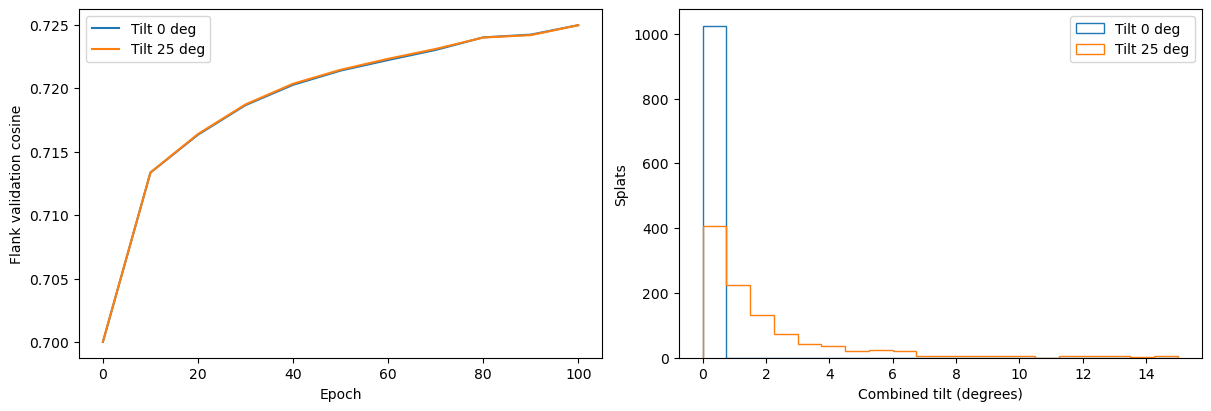

In [4]:
training = [(xyz[i][splits[i]['train']], values[i][splits[i]['train']]) for i in flanks]
train_xyz = torch.cat([x for x,y in training]); train_values = torch.cat([y for x,y in training])
validation = (torch.cat([xyz[i][splits[i]['validation']] for i in flanks]),
              torch.cat([values[i][splits[i]['validation']] for i in flanks]))
models, field_histories, field_rows = {}, {}, []
for tilt in TILT_LIMITS:
    name = f'Tilt {tilt:g} deg'
    model = initialize_field(train_xyz, train_values, ae, settings, tilt, SEED)
    path = CACHE/f'field_tilt_{tilt:g}.pt'
    if path.exists() and not FORCE_RETRAIN:
        saved = torch.load(path, map_location=device, weights_only=True)
        model.load_state_dict(saved['state']); history = saved['history']
        print('Loaded', name)
    else:
        if not RUN_FIELD_FITS: raise RuntimeError(f'Missing field cache: {path}')
        history = fit_field(model, training, validation, settings, SEED)
        torch.save(dict(state=model.state_dict(), history=history), path)
    model.eval(); model.requires_grad_(False)
    models[name] = model; field_histories[name] = history
    for cohort_name, x, y in [('Flank validation', *validation),
                              ('Unseen middle at released coordinates', xyz[1], values[1])]:
        field_rows.append(dict(model=name, cohort=cohort_name, **evaluate_field(model,x,y)))
display(pd.DataFrame(field_rows))
pd.DataFrame(field_rows).to_csv(FIGURES/'field_quality.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(12,4), constrained_layout=True)
for name, model in models.items():
    history = pd.DataFrame(field_histories[name])
    axes[0].plot(history.epoch, history.cosine, label=name)
    angles = torch.rad2deg(torch.linalg.vector_norm(model.splat_field.tilt_vectors(), dim=1)).detach().cpu().numpy()
    axes[1].hist(angles, bins=np.linspace(0,15,21), histtype='step', label=name)
axes[0].set(xlabel='Epoch', ylabel='Flank validation cosine'); axes[0].legend()
axes[1].set(xlabel='Combined tilt (degrees)', ylabel='Splats'); axes[1].legend()
save_figure(fig, 'field_training_and_tilt')


## Recover a known middle-section perturbation

The field is frozen. A rigid correction is fitted using middle training measurements, selected on middle validation measurements, and reported on untouched middle test measurements. The registration objective combines profile cosine, log-total signal error, weak pose regularization, and soft x-y support from the flanks. It receives neither the known inverse nor original middle coordinates.

The released coordinates are a **synthetic-recovery reference**, not guaranteed biological ground truth. The oracle restores those coordinates exactly and measures the field's interpolation error there; it is not guaranteed to maximize expression cosine. The unperturbed case detects unwanted drift. This is rigid recovery, not a non-affine benchmark or de novo volume assembly.


In [5]:
cases = [('Unperturbed',0.,(0.,0.)), ('Mild A',5.,(.02,-.02)),
         ('Mild B',-5.,(-.02,.02)), ('Strong A',15.,(.05,-.03)), ('Strong B',-15.,(-.05,.03))]
fit_idx, val_idx, test_idx = [splits[1][k] for k in ('train','validation','test')]
rows, mapped_cases = [], {}
for name, model in models.items():
    for case, degrees, shift in cases:
        print('Registration:', name, '|', case, flush=True)
        observed = perturb(xyz[1], degrees, shift)
        path = CACHE/f'registration_{name.replace(" ","_")}_{case.replace(" ","_")}.pt'
        if path.exists() and not FORCE_RETRAIN:
            from paper.volumetric_registration import SectionRigid
            saved = torch.load(path, map_location=device, weights_only=True)
            transform = SectionRigid(device); transform.load_state_dict(saved['state'])
        else:
            if not RUN_REGISTRATION: raise RuntimeError(f'Missing registration cache: {path}')
            transform, history = fit_transform(model, observed, values[1], fit_idx, val_idx,
                                               train_xyz, settings, SEED)
            torch.save(dict(state=transform.state_dict(), history=history), path)
        with torch.no_grad(): mapped = transform(observed)
        mapped_cases[name,case] = mapped.detach().cpu().numpy()
        for method, coordinates in [('Unregistered',observed), ('Recovered',mapped), ('Oracle coordinates',xyz[1])]:
            rows.append(dict(field=name, condition=case, method=method,
                             **recovery_metrics(model, coordinates[test_idx], xyz[1][test_idx], values[1][test_idx], cohort['unit'])))
results = pd.DataFrame(rows)
display(results)
results.to_csv(FIGURES/'frozen_field_recovery.csv', index=False)


Registration: Tilt 0 deg | Unperturbed
Registration: Tilt 0 deg | Mild A
Registration: Tilt 0 deg | Mild B
Registration: Tilt 0 deg | Strong A
Registration: Tilt 0 deg | Strong B
Registration: Tilt 25 deg | Unperturbed
Registration: Tilt 25 deg | Mild A
Registration: Tilt 25 deg | Mild B
Registration: Tilt 25 deg | Strong A
Registration: Tilt 25 deg | Strong B


,field,condition,method,loss,cosine,mae,rms_coordinate_error,q95_coordinate_error
0,Tilt 0 deg,Unperturbed,Unregistered,0.3321,0.7024,0.4675,4.762e-08,1.653e-07
1,Tilt 0 deg,Unperturbed,Recovered,0.332,0.7025,0.4675,0.06947,0.1145
2,Tilt 0 deg,Unperturbed,Oracle coordinates,0.3321,0.7024,0.4675,0,0
3,Tilt 0 deg,Mild A,Unregistered,0.357,0.6782,0.4807,0.4142,0.6176
4,Tilt 0 deg,Mild A,Recovered,0.3322,0.7023,0.4677,0.08803,0.1464
5,Tilt 0 deg,Mild A,Oracle coordinates,0.3321,0.7024,0.4675,0,0
6,Tilt 0 deg,Mild B,Unregistered,0.3617,0.6748,0.4786,0.415,0.6118
7,Tilt 0 deg,Mild B,Recovered,0.332,0.7025,0.4676,0.0727,0.1202
8,Tilt 0 deg,Mild B,Oracle coordinates,0.3321,0.7024,0.4675,0,0
9,Tilt 0 deg,Strong A,Unregistered,0.3941,0.6421,0.5002,1.015,1.541


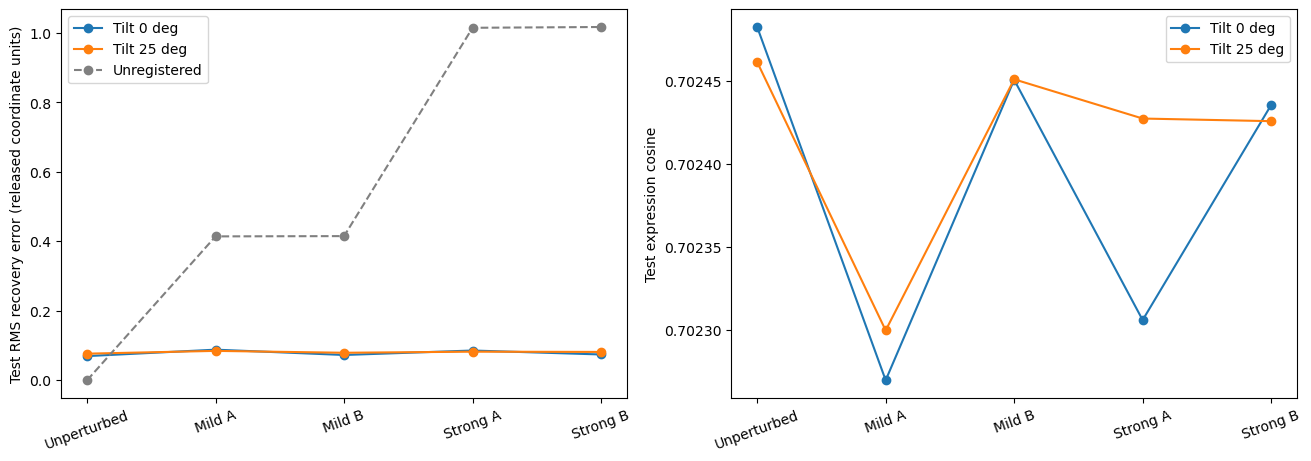

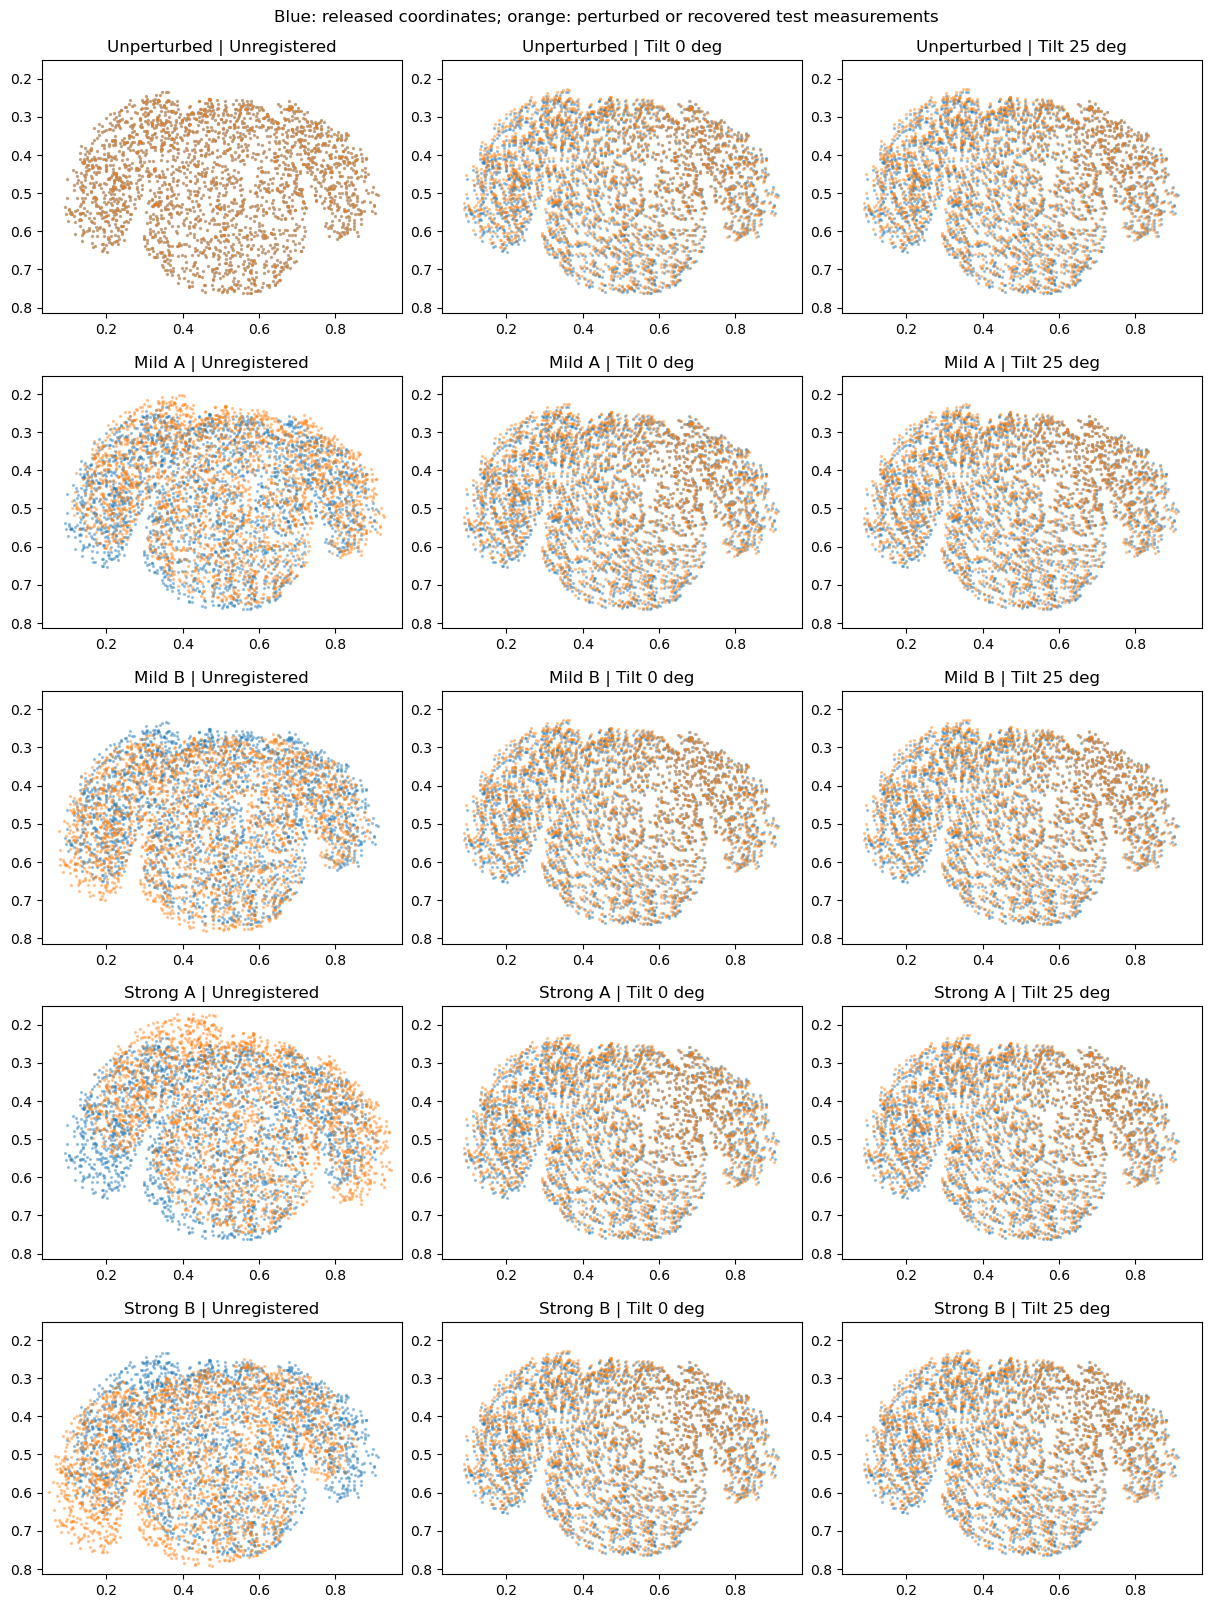

In [6]:
fig, axes = plt.subplots(1,2,figsize=(13,4.5), constrained_layout=True)
for name in models:
    group = results[(results.field==name)&(results.method=='Recovered')].set_index('condition').reindex([c[0] for c in cases])
    axes[0].plot(range(len(cases)), group.rms_coordinate_error, 'o-', label=name)
    axes[1].plot(range(len(cases)), group.cosine, 'o-', label=name)
before = results[(results.field==next(iter(models)))&(results.method=='Unregistered')].set_index('condition').reindex([c[0] for c in cases])
axes[0].plot(range(len(cases)), before.rms_coordinate_error, 'o--', color='0.5', label='Unregistered')
for ax in axes:
    ax.set_xticks(range(len(cases)), [c[0] for c in cases], rotation=20); ax.legend()
axes[0].set_ylabel('Test RMS recovery error (released coordinate units)')
axes[1].set_ylabel('Test expression cosine')
save_figure(fig, 'frozen_field_recovery')
truth = xyz[1][test_idx].cpu().numpy()
fig, axes = plt.subplots(len(cases),len(models)+1,figsize=(12,16), constrained_layout=True, squeeze=False)
all_points = [truth]+list(mapped_cases.values())+[perturb(xyz[1],a,t).cpu().numpy() for _,a,t in cases]
lo=np.concatenate(all_points).min(0); hi=np.concatenate(all_points).max(0)
for row,(case,angle,shift) in enumerate(cases):
    arrays=[perturb(xyz[1],angle,shift)[test_idx].cpu().numpy()]+[mapped_cases[name,case][test_idx.cpu().numpy()] for name in models]
    for ax,title,points in zip(axes[row],['Unregistered']+list(models),arrays):
        ax.scatter(truth[:,0],truth[:,1],s=2,alpha=.35,color='tab:blue')
        ax.scatter(points[:,0],points[:,1],s=2,alpha=.35,color='tab:orange')
        ax.set(title=f'{case} | {title}',aspect='equal',xlim=(lo[0]-.02,hi[0]+.02),ylim=(hi[1]+.02,lo[1]-.02))
fig.suptitle('Blue: released coordinates; orange: perturbed or recovered test measurements')
save_figure(fig, 'all_recovery_overlays')


## Compact recovery overlays

Display only Unperturbed, Mild A, and Strong A, labeled Unperturbed, Mild, and Strong. Both B perturbations are omitted from this figure only; the full figure and quantitative results above are unchanged. This cell reuses the existing registration outputs and performs no fitting.


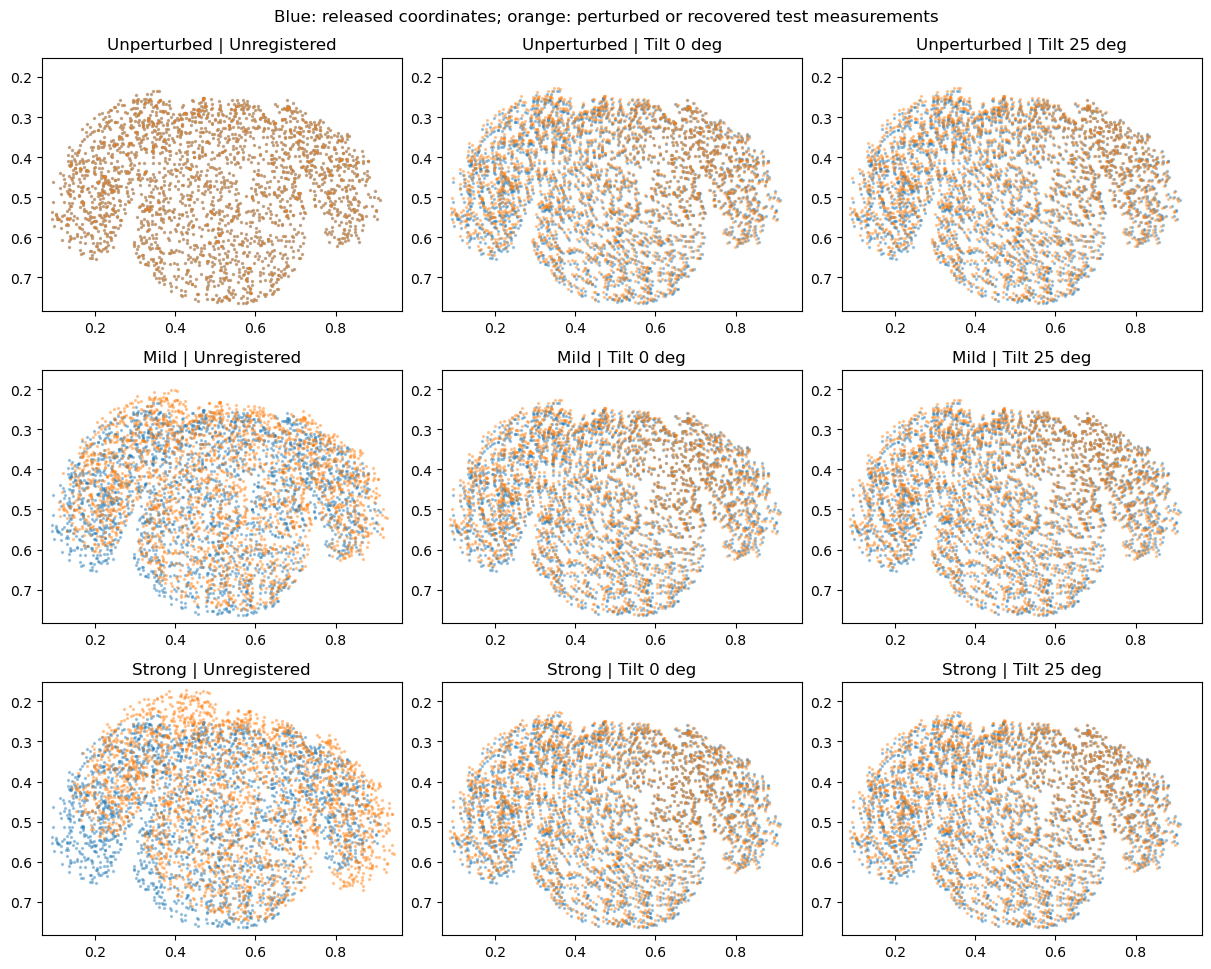

In [7]:
compact_labels = {'Unperturbed': 'Unperturbed', 'Mild A': 'Mild', 'Strong A': 'Strong'}
compact_cases = [next(c for c in cases if c[0] == name) for name in compact_labels]
compact_test_idx = test_idx.cpu().numpy()
compact_truth = xyz[1][test_idx].cpu().numpy()
compact_arrays = {}
for case, angle, shift in compact_cases:
    compact_arrays[case] = [perturb(xyz[1], angle, shift)[test_idx].cpu().numpy()] + [
        mapped_cases[name, case][compact_test_idx] for name in models]
compact_points = np.concatenate([compact_truth] + [a for arrays in compact_arrays.values() for a in arrays])
compact_lo, compact_hi = compact_points.min(0), compact_points.max(0)
fig, axes = plt.subplots(3, len(models)+1, figsize=(12, 9.6),
                         constrained_layout=True, squeeze=False)
for row, (case, _, _) in enumerate(compact_cases):
    for ax, title, points in zip(axes[row], ['Unregistered']+list(models), compact_arrays[case]):
        ax.scatter(compact_truth[:,0], compact_truth[:,1], s=2, alpha=.35, color='tab:blue')
        ax.scatter(points[:,0], points[:,1], s=2, alpha=.35, color='tab:orange')
        ax.set(title=f'{compact_labels[case]} | {title}', aspect='equal',
               xlim=(compact_lo[0]-.02, compact_hi[0]+.02),
               ylim=(compact_hi[1]+.02, compact_lo[1]-.02))
fig.suptitle('Blue: released coordinates; orange: perturbed or recovered test measurements')
save_figure(fig, 'compact_recovery_overlays')


## Three-plane geometry

Subsampled tissue measurements show the three planes. Wireframes show the top SHOW_TOP_PERCENT of splats ranked independently within each model. SPLAT_RANKING='usage' uses mean responsibility across all measurement coordinates, averaged equally across sections; 'opacity' instead uses learned sigmoid opacity. Opacity alone is not actual usage. Selection is descriptive only and does not affect training or checkpoint selection. Contours are visual aids, not hard kernel boundaries. Both panels use the same camera and fivefold z-axis display exaggeration; apparent angles and axis ratios are exaggerated. Set Z_DISPLAY_STRETCH to 1 for equal-unit geometry.


Tilt 0 deg: showing 52/1024 splats, top 5% by usage
Tilt 25 deg: showing 52/1024 splats, top 5% by usage


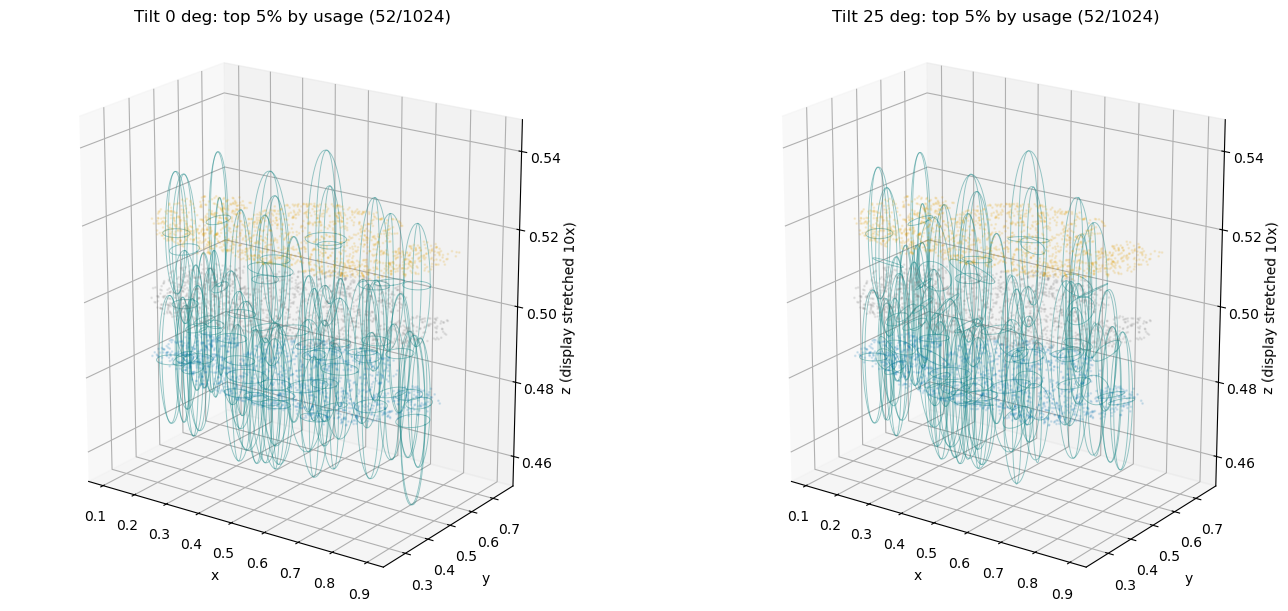

In [8]:
Z_DISPLAY_STRETCH = 10.0  # Display only; does not change model coordinates.
SHOW_TOP_PERCENT = 5.0
SPLAT_RANKING = 'usage'  # 'usage' or 'opacity'
if not 0 < SHOW_TOP_PERCENT <= 100: raise ValueError('SHOW_TOP_PERCENT must be in (0, 100]')
if SPLAT_RANKING not in {'usage', 'opacity'}: raise ValueError('Unknown SPLAT_RANKING')
fig = plt.figure(figsize=(14,6), constrained_layout=True)
for panel,(name,model) in enumerate(models.items(),start=1):
    ax=fig.add_subplot(1,len(models),panel,projection='3d')
    for i,x in enumerate(xyz):
        p=x[::max(1,len(x)//1500)].cpu().numpy()
        ax.scatter(*p.T,s=1,alpha=.12,color=['#0072b2','#777777','#e69f00'][i])
    means=model.means.detach().cpu().numpy(); scales=model.log_scales.exp().detach().cpu().numpy()
    tilt=model.splat_field.tilt_matrices().detach().cpu().numpy()
    rotation=model.rotation.detach().cpu().numpy().ravel()
    with torch.no_grad():
        if SPLAT_RANKING == 'opacity':
            scores = model.splat_field.opacity_logits.sigmoid().flatten()
        else:
            scores = torch.zeros(len(means), device=model.means.device)
            for points in xyz:
                for chunk in points.split(settings['batch_size']):
                    scores += model.splat_field.compute_weights(chunk).sum(0) / (len(points)*len(xyz))
    count = max(1, int(np.ceil(len(means)*SHOW_TOP_PERCENT/100)))
    selected = np.argsort(-scores.cpu().numpy(), kind='stable')[:count]
    print(f'{name}: showing {count}/{len(means)} splats, top {SHOW_TOP_PERCENT:g}% by {SPLAT_RANKING}')
    theta=np.linspace(0,2*np.pi,60)
    for k in selected:
        c,s=np.cos(rotation[k]),np.sin(rotation[k])
        rz=np.array([[c,-s,0],[s,c,0],[0,0,1]])
        for a,b in [(0,1),(0,2),(1,2)]:
            circle=np.zeros((len(theta),3)); circle[:,a]=np.cos(theta)*scales[k,a]; circle[:,b]=np.sin(theta)*scales[k,b]
            points=circle@(tilt[k]@rz).T+means[k]
            ax.plot(*points.T,color='#238b8b',alpha=.45,linewidth=.7)
    p=torch.cat(xyz).cpu().numpy(); low=p.min(0)-.03; high=p.max(0)+.03
    ax.set(xlim=(low[0],high[0]),ylim=(low[1],high[1]),zlim=(low[2],high[2]),title=f'{name}: top {SHOW_TOP_PERCENT:g}% by {SPLAT_RANKING} ({count}/{len(means)})',xlabel='x',ylabel='y',zlabel='z')
    ax.set_box_aspect((high-low)*np.array([1., 1., Z_DISPLAY_STRETCH]))
    ax.set_zlabel(f'z (display stretched {Z_DISPLAY_STRETCH:g}x)')
    ax.view_init(elev=20,azim=-55)
save_figure(fig,'three_section_splats')


## Do the splats actually connect sections?

For each splat, average responsibility is calculated separately on each section's test measurements. Equal section weighting avoids sample-count effects. A splat is called active if its average share is at least 0.1 times the uniform 1/number-of-splats share. Among active splats, a section contributes meaningfully if it supplies at least 20% of that splat's summed section-average responsibility. These are descriptive thresholds, not biological segmentation or proof of correct registration.

The middle section is evaluated at released coordinates here only to diagnose interpolation. These values do not select checkpoints. Tilt and z-center plots expose excessive tilt, cap accumulation, and slice-specific support.


,model,active_splats,fraction_active_multisection,median_tilt_degrees,centers_outside_flanks
0,Tilt 0 deg,1000,0.674,0,0
1,Tilt 25 deg,998,0.6583,1.047,0


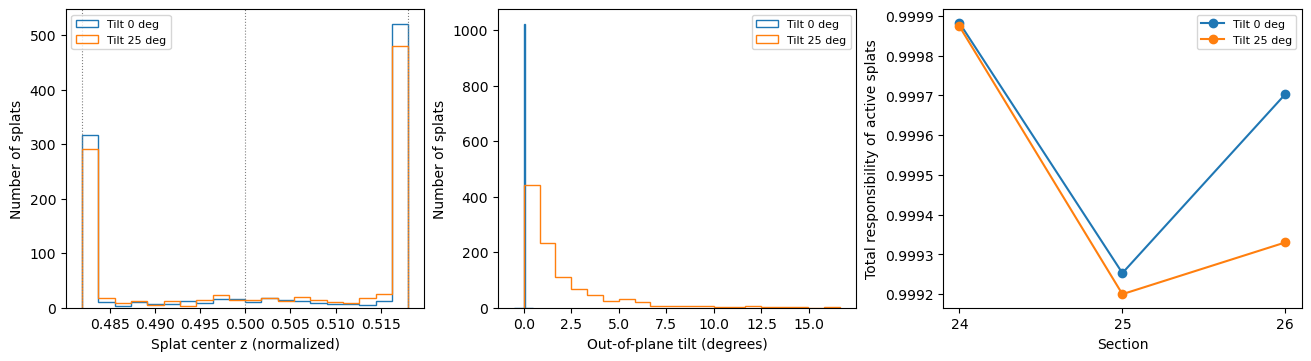

In [9]:
sharing_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for name, model in models.items():
    with torch.no_grad():
        section_mass = []
        for i in range(3):
            points = xyz[i][splits[i]['test']]
            mass = torch.zeros(settings['num_splats'], device=device)
            for chunk in points.split(settings['batch_size']):
                mass += model.splat_field.compute_weights(chunk).sum(0)
            section_mass.append(mass / len(points))
        mass = torch.stack(section_mass)
        active = mass.mean(0) >= .1 / settings['num_splats']
        shares = mass / mass.sum(0, keepdim=True).clamp_min(1e-12)
        shared = (shares >= .2).sum(0) >= 2
        angles = torch.rad2deg(torch.linalg.vector_norm(model.splat_field.tilt_vectors(), dim=1))
        centers = model.means[:, 2]
        zlo, zhi = train_xyz[:, 2].min(), train_xyz[:, 2].max()
        sharing_rows.append(dict(model=name, active_splats=int(active.sum()),
            fraction_active_multisection=float(shared[active].float().mean()) if active.any() else np.nan,
            median_tilt_degrees=float(angles.median()),
            centers_outside_flanks=int(((centers < zlo-1e-6) | (centers > zhi+1e-6)).sum())))
        axes[0].hist(centers.cpu().numpy(), bins=20, histtype='step', label=name)
        axes[1].hist(angles.cpu().numpy(), bins=20, histtype='step', label=name)
        axes[2].plot(np.arange(3), mass[:, active].sum(1).cpu().numpy(), 'o-', label=name)
for i in range(3):
    axes[0].axvline(float(xyz[i][:, 2].median()), color='gray', linestyle=':', linewidth=.8)
axes[0].set(xlabel='Splat center z (normalized)', ylabel='Number of splats')
axes[1].set(xlabel='Out-of-plane tilt (degrees)', ylabel='Number of splats')
axes[2].set(xticks=range(3), xticklabels=SECTIONS, xlabel='Section',
            ylabel='Total responsibility of active splats')
for ax in axes:
    ax.legend(fontsize=8)
display(pd.DataFrame(sharing_rows))
pd.DataFrame(sharing_rows).to_csv(CACHE/'cross_plane_support.csv', index=False)
save_figure(fig, 'cross_plane_support')


## Optional joint three-section experiment

Enable `RUN_JOINT` only after checking frozen-field recovery. This stage uses all three sections for field training with disjoint within-section validation/test measurements. The middle section's transform and all z coordinates stay fixed. Outer sections receive known perturbations, but their original coordinates never enter fitting or initialization.

Both the fixed-pose control and alternating model start from the same field initialized from **perturbed training observations**, with the same number of field updates. The alternating model additionally optimizes outer poses. The shared decoder remains frozen. Validation expression selects the joint checkpoint; synthetic recovery error is used only for reporting. This can reveal whether a flexible field absorbs misalignment rather than correcting it. No claim of fully identified anatomy follows from a low reconstruction loss.


In [10]:
joint_rows=[]
if RUN_JOINT:
    observed=[perturb(xyz[0],10.,(.03,-.02)),xyz[1].clone(),perturb(xyz[2],-10.,(-.03,.02))]
    train_indices=[s['train'] for s in splits]; validation_indices=[s['validation'] for s in splits]
    joint_xyz=torch.cat([x[idx] for x,idx in zip(observed,train_indices)])
    joint_values=torch.cat([y[idx] for y,idx in zip(values,train_indices)])
    for tilt in TILT_LIMITS:
        initial=initialize_field(joint_xyz,joint_values,ae,settings,tilt,SEED)
        for adjust in (False,True):
            model=copy.deepcopy(initial)
            mode='Joint poses' if adjust else 'Fixed poses'
            joint_settings=dict(settings,joint_steps=settings['joint_steps'] if adjust else settings['joint_steps']//2)
            path=CACHE/f'joint_{tilt:g}_{adjust}.pt'
            if path.exists() and not FORCE_RETRAIN:
                from paper.volumetric_registration import SectionRigid
                saved=torch.load(path,map_location=device,weights_only=True)
                model.load_state_dict(saved['field'])
                transforms=[SectionRigid(device) for _ in observed]
                for t,state in zip(transforms,saved['transforms']): t.load_state_dict(state)
            else:
                transforms,history=fit_joint(model,observed,values,train_indices,validation_indices,joint_settings,SEED,update_transforms=adjust)
                torch.save(dict(field=model.state_dict(),transforms=[t.state_dict() for t in transforms],history=history),path)
            for i in range(3):
                idx=splits[i]['test']
                with torch.no_grad(): mapped=transforms[i](observed[i][idx])
                joint_rows.append(dict(tilt_limit=tilt,method=mode,section=cohort['blocks'][i]['label'],
                    **recovery_metrics(model,mapped,xyz[i][idx],values[i][idx],cohort['unit'])))
    joint_results=pd.DataFrame(joint_rows)
    display(joint_results)
    joint_results.to_csv(FIGURES/'joint_registration.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    for (tilt,method),group in joint_results.groupby(['tilt_limit','method']):
        label=f'{method}, tilt {tilt:g}'
        axes[0].plot(range(3),group.rms_coordinate_error,'o-',label=label)
        axes[1].plot(range(3),group.cosine,'o-',label=label)
    for ax in axes: ax.set_xticks(range(3),['Lower','Middle (fixed)','Upper']); ax.legend(fontsize=8)
    axes[0].set_ylabel('Test RMS recovery error'); axes[1].set_ylabel('Test expression cosine')
    save_figure(fig,'joint_vs_fixed_pose')
else:
    print('Joint experiment disabled; frozen-field analysis is complete.')


Joint experiment disabled; frozen-field analysis is complete.


## Decision criteria

- First require a field that predicts the middle section reasonably at the released coordinates. Poor interpolation makes registration hard to interpret.
- A useful registration signal should reduce known coordinate error relative to the perturbed input and avoid drifting on the unperturbed control.
- Bounded tilt helps registration only if it improves recovery, not merely expression fit. Tilt near its limit is a warning to examine identifiability, not an automatic reason to loosen it.
- In the joint experiment, expression gains without pose recovery suggest the field is absorbing misalignment. Compare with the fixed-pose control before attributing benefits to registration.
- These are repeated perturbations of one donor triplet. Do not treat them as independent biological replicates or tune repeatedly on final test errors. A second triplet is the next validation step.


## Synthetic tilt visualization check

These are artificial splats, not fitted results. The columns impose 0, 25, and 60 degree out-of-plane rotations using the production model's tilt implementation with an 85-degree limit for this diagnostic only. The top row uses equal units; the bottom uses the current Z_DISPLAY_STRETCH. Both rows use the same camera, scales, and center. Orange lines show the local depth axis, dashed lines the world vertical, and translucent planes indicate three section depths. Reported post-stretch angles are 3D display-space angles before camera projection. No training, cached model, or model setting is modified. Run the setup/data cells for save_figure, or use the existing session.


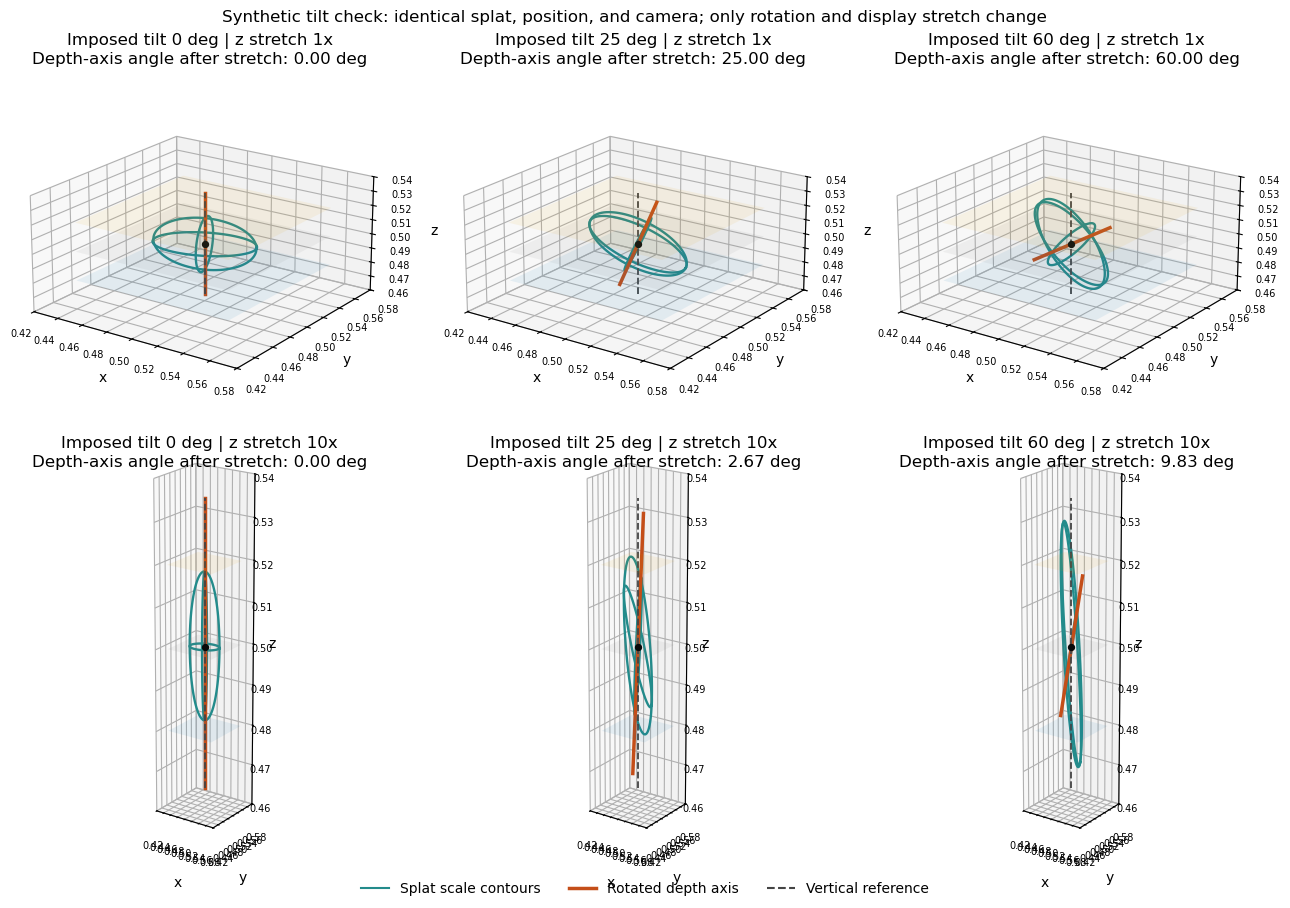

In [11]:
# Synthetic visualization only: no fitting and no changes to saved models.
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.lines import Line2D
from spatsplat import VolumetricAmplitudeSplatField

SYNTHETIC_TILTS = [0., 25., 60.]
SYNTHETIC_Z_STRETCH = float(globals().get('Z_DISPLAY_STRETCH', 10.))
# Use the production rotation implementation with an intentionally larger limit.
with torch.random.fork_rng(devices=[]):
    demo = VolumetricAmplitudeSplatField(3, 2, 4, 3, max_tilt_degrees=85.)
with torch.no_grad():
    for k, angle in enumerate(SYNTHETIC_TILTS):
        ratio = angle / 85.
        demo.splat_field.tilt_raw[k].zero_()
        demo.splat_field.tilt_raw[k, 1] = ratio / np.sqrt(1-ratio**2)
    demo_tilts = demo.splat_field.tilt_matrices().cpu().numpy()
    measured = torch.rad2deg(demo.splat_field.tilt_vectors().norm(dim=1)).cpu().numpy()
np.testing.assert_allclose(measured, SYNTHETIC_TILTS, atol=1e-5)
center = np.array([.5, .5, .5])
demo_scales = np.array([.035, .022, .018])
theta = np.linspace(0, 2*np.pi, 100)
yaw = np.deg2rad(20.)
rz = np.array([[np.cos(yaw), -np.sin(yaw), 0],
               [np.sin(yaw), np.cos(yaw), 0], [0, 0, 1.]])
low, high = np.array([.42, .42, .46]), np.array([.58, .58, .54])
fig = plt.figure(figsize=(13, 9), constrained_layout=True)
for row, stretch in enumerate([1., SYNTHETIC_Z_STRETCH]):
    for col, angle in enumerate(SYNTHETIC_TILTS):
        ax = fig.add_subplot(2, 3, row*3+col+1, projection='3d')
        rotation = demo_tilts[col] @ rz
        for z, color in zip([.48, .5, .52], ['#0072b2', '#777777', '#e69f00']):
            xx, yy = np.meshgrid([.44, .56], [.44, .56])
            ax.plot_surface(xx, yy, np.full_like(xx, z), color=color, alpha=.08, shade=False)
        for a, b in [(0, 1), (0, 2), (1, 2)]:
            circle = np.zeros((len(theta), 3))
            circle[:, a] = np.cos(theta)*demo_scales[a]
            circle[:, b] = np.sin(theta)*demo_scales[b]
            points = circle @ rotation.T + center
            # The same local-to-world transform used in the fitted-field figure.
            radius = (((points-center) @ rotation)/demo_scales)**2
            np.testing.assert_allclose(radius.sum(1), 1., atol=2e-6)
            ax.plot(*points.T, color='#238b8b', linewidth=1.7)
        axis = center + np.array([-.035, .035])[:, None]*rotation[:, 2]
        vertical = center + np.array([[0, 0, -.035], [0, 0, .035]])
        ax.plot(*axis.T, color='#c44e19', linewidth=2.5)
        ax.plot(*vertical.T, color='#444444', linestyle='--', linewidth=1.3)
        ax.scatter(*center, color='black', s=18)
        apparent = np.degrees(np.arctan(np.tan(np.deg2rad(angle))/stretch))
        ax.set(title=f'Imposed tilt {angle:g} deg | z stretch {stretch:g}x\n'
                     f'Depth-axis angle after stretch: {apparent:.2f} deg',
               xlim=(low[0], high[0]), ylim=(low[1], high[1]), zlim=(low[2], high[2]),
               xlabel='x', ylabel='y', zlabel='z')
        ax.set_box_aspect((high-low)*np.array([1., 1., stretch]))
        ax.view_init(elev=20, azim=-55)
        ax.tick_params(labelsize=7)
fig.suptitle('Synthetic tilt check: identical splat, position, and camera; only rotation and display stretch change',
             fontsize=12)
fig.legend(handles=[
    Line2D([], [], color='#238b8b', label='Splat scale contours'),
    Line2D([], [], color='#c44e19', linewidth=2.5, label='Rotated depth axis'),
    Line2D([], [], color='#444444', linestyle='--', label='Vertical reference')],
    loc='outside lower center', ncol=3, frameon=False)
save_figure(fig, 'synthetic_tilt_visualization_check')


## Three-plane geometry: highest learned tilts

Same tissue measurements, camera, wireframe contours, limits, and z stretching as the standard volumetric view. Only selection changes: TOP_TILT_PERCENT selects the largest actual learned out-of-plane angles, independently within each tilt-enabled model. Zero-tilt controls are omitted because their angles are all zero. These are fitted splats, not synthetic rotations. The title reports their angle range; z stretching still distorts apparent angles. Run after loading the fitted models; no retraining is needed.


Tilt 25 deg: showing 52/1024 splats, top 5% by learned tilt
Selected tilt range: 6.573 to 16.64 degrees


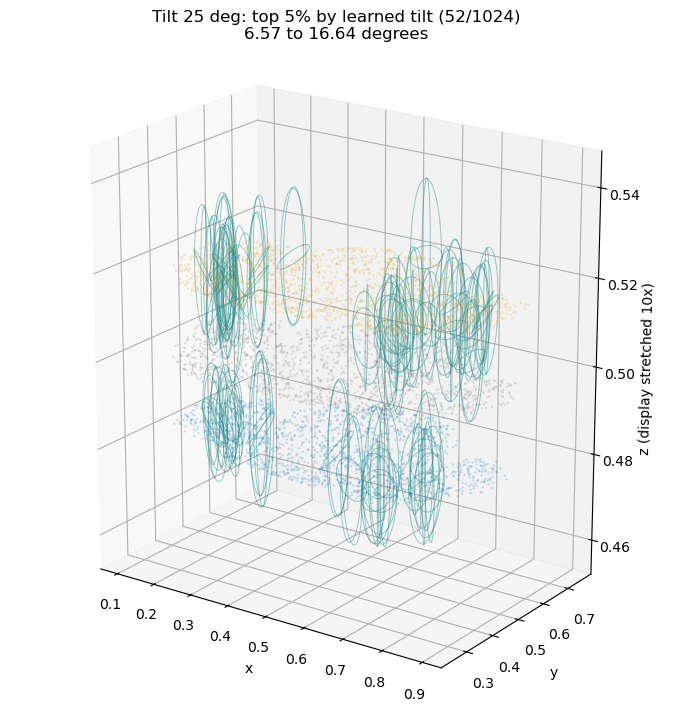

In [12]:
TILT_VIEW_Z_STRETCH = float(globals().get('Z_DISPLAY_STRETCH', 10.))
TOP_TILT_PERCENT = 5.0
if not 0 < TOP_TILT_PERCENT <= 100: raise ValueError('TOP_TILT_PERCENT must be in (0, 100]')
tilted_models = [(name, model) for name, model in models.items()
                 if model.splat_field.max_tilt_degrees > 0]
if not tilted_models: raise RuntimeError('Load a fitted model with tilt enabled first.')
fig = plt.figure(figsize=(8*len(tilted_models), 7), constrained_layout=True)
for panel,(name,model) in enumerate(tilted_models,start=1):
    ax=fig.add_subplot(1,len(tilted_models),panel,projection='3d')
    for i,x in enumerate(xyz):
        p=x[::max(1,len(x)//1500)].cpu().numpy()
        ax.scatter(*p.T,s=1,alpha=.12,color=['#0072b2','#777777','#e69f00'][i])
    means=model.means.detach().cpu().numpy(); scales=model.log_scales.exp().detach().cpu().numpy()
    tilt=model.splat_field.tilt_matrices().detach().cpu().numpy()
    rotation=model.rotation.detach().cpu().numpy().ravel()
    with torch.no_grad():
        scores = torch.rad2deg(model.splat_field.tilt_vectors().norm(dim=1))
    count = max(1, int(np.ceil(len(means)*TOP_TILT_PERCENT/100)))
    selected = np.argsort(-scores.cpu().numpy(), kind='stable')[:count]
    print(f'{name}: showing {count}/{len(means)} splats, top {TOP_TILT_PERCENT:g}% by learned tilt')
    chosen_angles = scores.cpu().numpy()[selected]
    print(f'Selected tilt range: {chosen_angles.min():.4g} to {chosen_angles.max():.4g} degrees')
    theta=np.linspace(0,2*np.pi,60)
    for k in selected:
        c,s=np.cos(rotation[k]),np.sin(rotation[k])
        rz=np.array([[c,-s,0],[s,c,0],[0,0,1]])
        for a,b in [(0,1),(0,2),(1,2)]:
            circle=np.zeros((len(theta),3)); circle[:,a]=np.cos(theta)*scales[k,a]; circle[:,b]=np.sin(theta)*scales[k,b]
            points=circle@(tilt[k]@rz).T+means[k]
            ax.plot(*points.T,color='#238b8b',alpha=.45,linewidth=.7)
    p=torch.cat(xyz).cpu().numpy(); low=p.min(0)-.03; high=p.max(0)+.03
    ax.set(xlim=(low[0],high[0]),ylim=(low[1],high[1]),zlim=(low[2],high[2]),title=f'{name}: top {TOP_TILT_PERCENT:g}% by learned tilt ({count}/{len(means)})\n{chosen_angles.min():.2f} to {chosen_angles.max():.2f} degrees',xlabel='x',ylabel='y',zlabel='z')
    ax.set_box_aspect((high-low)*np.array([1., 1., TILT_VIEW_Z_STRETCH]))
    ax.set_zlabel(f'z (display stretched {TILT_VIEW_Z_STRETCH:g}x)')
    ax.view_init(elev=20,azim=-55)
save_figure(fig,'three_section_highest_tilt_splats')


## Interactive highest-tilt splats

Same fitted splat selection and geometry as the static highest-tilt view. Drag to rotate, scroll to zoom, and hover over contours or centers for splat IDs and learned angles. The buttons toggle equal-unit geometry and stretched z without changing model coordinates. A self-contained HTML file is exported under the current FIGURES directory and works offline if inline display is unavailable. Plotly is required; no retraining is performed.


In [13]:
# Requires fitted models and coordinates, not a new fit.
from paper import volumetric_registration_plots as volume_plots
import importlib
importlib.reload(volume_plots)

INTERACTIVE_TOP_TILT_PERCENT = float(globals().get('TOP_TILT_PERCENT', 5.))
INTERACTIVE_Z_STRETCH = float(globals().get('TILT_VIEW_Z_STRETCH',
                                         globals().get('Z_DISPLAY_STRETCH', 10.)))
interactive_tilt_figures = {}
for name, model in models.items():
    if model.splat_field.max_tilt_degrees <= 0:
        continue
    interactive = volume_plots.highest_tilt_figure(
        model, xyz, name=name, top_percent=INTERACTIVE_TOP_TILT_PERCENT,
        z_stretch=INTERACTIVE_Z_STRETCH, section_labels=SECTIONS)
    interactive_tilt_figures[name] = interactive
    filename = f'three_section_highest_tilt_{model.splat_field.max_tilt_degrees:g}deg_interactive.html'
    path = FIGURES/filename
    interactive.write_html(path, include_plotlyjs=True, full_html=True,
                           config={'scrollZoom': True, 'displaylogo': False})
    print('Standalone interactive figure:', path)
    interactive.show(renderer='plotly_mimetype',
                     config={'scrollZoom': True, 'displaylogo': False})
if not interactive_tilt_figures:
    raise RuntimeError('Load a fitted model with tilt enabled first.')


Standalone interactive figure: /home/javeda/Documents/Research/spatsplat-registration/figures/volumetric_registration_benchmark/e39f611b3e551277/three_section_highest_tilt_25deg_interactive.html


## Publication figure: spatial context and equal-scale geometry

A shows tissue measurements and splat centers, with display-exaggerated z and colors encoding true tilt. The overview includes the top 5% by section-balanced mean responsibility plus the maximum-tilt splat. B shows the maximum-tilt example; C shows the lower-median tilt among that high-usage subset. The examples are not chosen for appearance. Dotted connectors identify their positions in A.

B-C are orthographic side-view silhouettes of the fitted ellipsoids in their respective tilt planes, not tissue-plane intersections. Both use the same equal coordinate scale; orange depth-axis lines are extended for orientation and do not mark kernel boundaries. No fitting occurs. Source splat IDs, angles, sizes, and selection rules are exported alongside the PNG/PDF.


,panel,splat,selection,tilt_degrees,mean_responsibility,center,scales
0,B,997,Maximum tilt,16.64,0.001762,"[0.2341657280921936, 0.49456673860549927, 0.51...","[0.019607380032539368, 0.04520419239997864, 0...."
1,C,189,Median tilt among high-usage splats,1.418,0.0009079,"[0.6060834527015686, 0.41671693325042725, 0.49...","[0.030619950965046883, 0.029598623514175415, 0..."


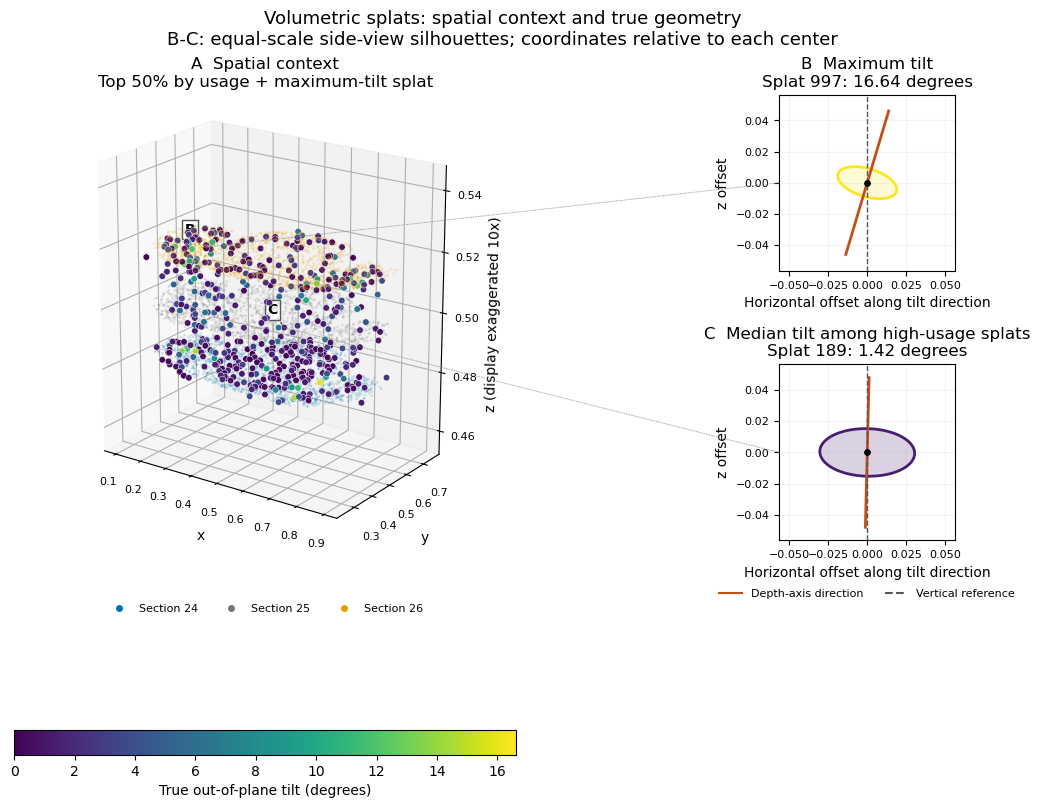

In [14]:
from paper import volumetric_registration_publication as volume_publication
import importlib
importlib.reload(volume_publication)

PUBLICATION_TOP_USAGE_PERCENT = 50.
PUBLICATION_Z_STRETCH = float(globals().get('Z_DISPLAY_STRETCH', 10.))
publication_tilt_models = [(name, model) for name, model in models.items()
                           if model.splat_field.max_tilt_degrees > 0]
if not publication_tilt_models:
    raise RuntimeError('Load a fitted tilt-enabled model first.')
for name, model in publication_tilt_models:
    publication_fig, publication_examples = volume_publication.tilt_publication_figure(
        model, xyz, section_labels=SECTIONS,
        top_usage_percent=PUBLICATION_TOP_USAGE_PERCENT,
        z_stretch=PUBLICATION_Z_STRETCH, batch_size=settings['batch_size'])
    display(pd.DataFrame(publication_examples))
    stem = f'three_section_tilt_publication_{model.splat_field.max_tilt_degrees:g}deg'
    (FIGURES/f'{stem}_examples.json').write_text(json.dumps(publication_examples, indent=2))
    save_figure(publication_fig, stem)
